# 8 · Real hardware

*Roadmap:* [1 · Teleportation](01_teleportation.ipynb) → [2 · Channel noise](02_channel_noise.ipynb) → [3 · Correction from counts](03_correction_from_counts.ipynb) → [4 · Automatic recalibration](04_automatic_recalibration.ipynb) → [5 · Incoherent noise and the ceiling](05_incoherent_noise_and_ceiling.ipynb) → [6 · Correlated noise](06_correlated_noise.ipynb) → [7 · Efficient learning and tracking](07_efficient_learning_and_tracking.ipynb) → **8 · Real hardware** → [9 · Replication](09_replication.ipynb)

**Question.** Notebooks 1–7 built the correction and tested it in simulation. Does it work on a real quantum computer,
which has errors of its own that nobody gave us, when the correction is learned from that computer's counts only?

**The experiment.** On 4 October 2026 the protocol ran on the IBM device `ibm_kingston` in two rounds.
*Round 1* measured the device, injected the coherent channel error N1 of notebook 2 and learned the correction with
TOMO-9 (notebook 7). *Round 2* ran the learned corrections. Each job and its predicted outcome were fixed and
hashed before the job was sent (`data/README.md`). This notebook rebuilds every hardware result from the raw counts
in `data/`: no account, no quantum computer and no simulator are needed. *Runtime: about 30 s.*

**Reminder of the circuit.** Six qubits: q0, q1 carry Alice's message, (q2, q4) and (q3, q5) are the two Bell pairs,
q4, q5 are Bob's. The channel error acts on q2, q3; the correction is a rotation U(θ, φ, λ) on each of q2, q3.
Version A applies Bob's corrections in software (Pauli frame) and is used everywhere unless stated; version B uses
mid-circuit measurement and feed-forward, version C deferred measurement. Two messages: `product_HT` (H then T on each
qubit) and `bell_30_70` = √0.3|00⟩ + √0.7|11⟩.

In [1]:
import sys
try:
    import telecorr
except ImportError:                       # running from a source checkout without installation
    sys.path.insert(0, "../src"); import telecorr

import time
import numpy as np
import matplotlib.pyplot as plt
from telecorr.hardware import analysis as A, data as D
from telecorr.hardware.__main__ import check
from telecorr.hardware.budget import CHAIN
from telecorr.hardware.frame import frame_counts, raw_counts
from telecorr.paulis import pauli_2q
from telecorr.rotations import NOMINAL_NOISE
from telecorr.states import message_state
from telecorr.plotting import use_style, CONDITION, SLOTS, INK, INK_2, bar_labels
from telecorr.report import md_table, show, fmt
use_style()

t0 = time.time()
out = A.reproduce()                       # the whole hardware analysis, from the raw counts
print(f"telecorr {telecorr.__version__}: hardware analysis done in {time.time() - t0:.1f} s")
r1, r2 = out["r1"], out["r2"]
STATES = ("product_HT", "bell_30_70")
F = lambda key: (r1["tomo"].get(key) or r2["tomo"][key])["F"]            # noqa: E731
S = lambda key: (r1["tomo"].get(key) or r2["tomo"][key])["F_sigma"]      # noqa: E731

telecorr 1.1.0: hardware analysis done in 15.0 s


## 1. The four jobs

In [2]:
PURPOSE = {"pilot (R0)": "measure the cost per shot", "Round 1": "measure the device, learn the corrections",
           "Round 2 main": "run the learned corrections", "Round 2 DD": "the same with dynamical decoupling"}
rows = [(j["job"], PURPOSE[j["job"]], j["shots"], j["usage_s"]) for j in out["jobs"]]
show(md_table(rows, ["job", "purpose", "shots", "QPU time (s)"], 0))
show(f"Total: **{sum(j['usage_s'] for j in out['jobs'])} s** of QPU time. The IBM job ids and timings are in `data/README.md`.")

| job | purpose | shots | QPU time (s) |
|---|---|---|---|
| pilot (R0) | measure the cost per shot | 5000 | 4 |
| Round 1 | measure the device, learn the corrections | 436000 | 117 |
| Round 2 main | run the learned corrections | 210000 | 58 |
| Round 2 DD | the same with dynamical decoupling | 54000 | 17 |

Total: **196 s** of QPU time. The IBM job ids and timings are in `data/README.md`.

## 2. How Bob's fidelity is measured

**Pauli frame.** Alice's four bits decide Bob's corrections: bits 0 / 1 (q0 / q1) give the Z correction of q4 / q5,
bits 2 / 3 (q2 / q3) the X correction. When Bob measures in a Pauli basis, an X correction flips a Z or Y result and a
Z correction flips an X or Y result:

$$\text{flip}(Z) = x,\qquad \text{flip}(X) = z,\qquad \text{flip}(Y) = x \oplus z .$$

Flipping the recorded bits shot by shot is the same as correcting before the measurement (Theorem T8.1, test
`test_T8_1_pauli_frame_equals_live_correction`). Without the frame Bob's results are random; with it they show the
message.

In [3]:
d1 = D.load_round(1)
lab = "R1_nativeA_product_HT_XX"          # device alone, message product_HT, Bob measured in basis XX
a, b_ = np.array(d1[lab]["ints"]["alice"]), np.array(d1[lab]["ints"]["bob"])
raw, fr = raw_counts(b_), frame_counts(a, b_, "XX")
xx = lambda c: (c["00"] - c["01"] - c["10"] + c["11"]) / sum(c.values())    # noqa: E731
psi = message_state("product_HT")
show(md_table([("Bob's bits as recorded", *raw.values(), xx(raw)), ("after the Pauli frame", *fr.values(), xx(fr))],
              ["device alone, product_HT, basis XX", *[f"b5b4 = {k}" for k in raw], "⟨XX⟩"], 4))
show(f"Ideal value: ⟨XX⟩ = {float(np.real(psi.conj() @ pauli_2q('X', 'X') @ psi)):.4f}.")

| device alone, product_HT, basis XX | b5b4 = 00 | b5b4 = 01 | b5b4 = 10 | b5b4 = 11 | ⟨XX⟩ |
|---|---|---|---|---|---|
| Bob's bits as recorded | 775 | 716 | 752 | 757 | 0.0213 |
| after the Pauli frame | 1988 | 485 | 418 | 109 | 0.3980 |

Ideal value: ⟨XX⟩ = 0.5000.

**Readout.** Four pattern circuits give each qubit's flip probabilities e0 = P(1|0) and e1 = P(0|1). A Pauli
expectation read through such a bit is shrunk to (1 − e0 − e1)⟨P⟩ + (e1 − e0) (T8.2). Bob's own readout can be
inverted exactly (*Bob-only mitigation*), but Alice's cannot: a wrong Alice bit is a wrong correction, a real
teleportation error. The main results therefore use the raw (unmitigated) counts.

**State tomography.** Bob is measured in the 9 Pauli bases. The *linear* estimate ρ̂ gives F = ⟨ψ|ρ̂|ψ⟩, which is
linear in the observed frequencies, hence unbiased, with an exact multinomial variance (T8.3). Error bars σ come from
300 bootstrap resamples per block.

In [4]:
ro, cal = r1["readout"], out["chain_calibration"]["qubits"]
ROLE = ["message", "message", "channel", "channel", "Bob", "Bob"]
rows = [(f"q{i}", f"Q{CHAIN[f'q{i}']}", ROLE[i], ro["e0"][i], ro["e1"][i], cal[f"q{i}"]["prob_meas1_prep0"], cal[f"q{i}"]["prob_meas0_prep1"])
        for i in range(6)]
show(md_table(rows, ["qubit", "on the device", "role", "e0 measured", "e1 measured", "e0 IBM record", "e1 IBM record"], 4))
show(f"The largest error is e1 of the message qubit q0: **{ro['e1'][0]:.4f}** measured, against {cal['q0']['prob_meas0_prep1']:.4f} "
     "in IBM's calibration record of that day.")

| qubit | on the device | role | e0 measured | e1 measured | e0 IBM record | e1 IBM record |
|---|---|---|---|---|---|---|
| q0 | Q41 | message | 0.0200 | 0.0594 | 0.0020 | 0.0059 |
| q1 | Q42 | message | 0.0019 | 0.0061 | 0.0005 | 0.0059 |
| q2 | Q36 | channel | 0.0009 | 0.0145 | 0 | 0.0107 |
| q3 | Q43 | channel | 0.0006 | 0.0073 | 0.0010 | 0.0107 |
| q4 | Q21 | Bob | 0.0015 | 0.0080 | 0.0005 | 0.0054 |
| q5 | Q44 | Bob | 0.0021 | 0.0103 | 0.0024 | 0.0107 |

The largest error is e1 of the message qubit q0: **0.0594** measured, against 0.0059 in IBM's calibration record of that day.

## 3. The device, and the injected error (Round 1)

Three reference blocks: the device alone, the device with the coherent channel error N1 of notebook 2 injected on q2,
q3 (rotations of 0.5 and 1.3 rad), and N1 followed by its exact inverse (the *oracle*, the best a correction that
knows N1 could do).

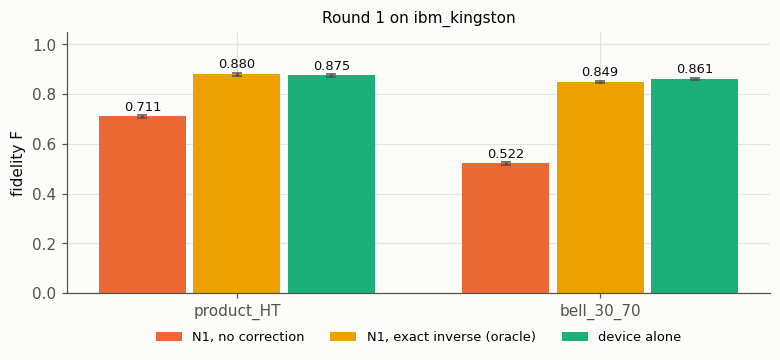

The device alone reaches F = 0.875 / 0.861; N1 lowers it to 0.711 / 0.522, and the oracle brings it back to 0.880 / 0.849 (product_HT / bell_30_70). The device's own errors cost 1 − F = 0.125 / 0.139 before any channel error is added; section 7 shows where this goes.

In [5]:
keys = [("R1_N1none", "no correction"), ("R1_N1oracle", "oracle (exact inverse)"), ("R1_nativeA", "native (no injected noise)")]
fig, ax = plt.subplots(figsize=(7.2, 3.4)); w = 0.26
for i, (pre, cond) in enumerate(keys):
    bars = ax.bar(np.arange(2) + (i - 1) * w, [F(f"{pre}_{st}") for st in STATES], w * 0.92, yerr=[S(f"{pre}_{st}") for st in STATES],
                  color=CONDITION[cond], label=A.NAMES[pre], capsize=3, ecolor=INK_2)
    bar_labels(ax, bars, pad=0.012)
ax.set_xticks(range(2), STATES); ax.set_ylim(0, 1.05); ax.set_ylabel("fidelity F")
ax.set_title("Round 1 on ibm_kingston", fontsize=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8.5); plt.tight_layout(); plt.show()
show("The device alone reaches F = " + " / ".join(f"{F(f'R1_nativeA_{st}'):.3f}" for st in STATES)
     + "; N1 lowers it to " + " / ".join(f"{F(f'R1_N1none_{st}'):.3f}" for st in STATES)
     + ", and the oracle brings it back to " + " / ".join(f"{F(f'R1_N1oracle_{st}'):.3f}" for st in STATES)
     + " (product_HT / bell_30_70). The device's own errors cost 1 − F = "
     + " / ".join(f"{1 - F(f'R1_nativeA_{st}'):.3f}" for st in STATES)
     + " before any channel error is added; section 7 shows where this goes.")

## 4. Learning the correction from real counts (TOMO-9)

TOMO-9 (notebook 7) applies three known settings S ∈ {I, C, C²} (C = a 120° rotation about (1, 1, 1)) in the correction
box and teleports three probe states, each read in its own axis: 9 circuits. Alice's random outcomes twirl each leg of
the channel, so the measured shrink factors are linear in the leg's 3 × 3 matrix T,

$$\lambda_{ja} = \sum_c (S_j)_{ac}\, T_{ca},$$

and 9 numbers per leg fix T. The best correction is the rotation R that maximises tr(R T), found in closed form by
orthogonal Procrustes (notebook 5). TOMO-9 was run on the device alone, with N1, and with an 8 µs wait (section 6).

In [6]:
rows = []
for kind, what in (("fingerprint", "device alone"), ("cal9", "with N1"), ("calN2", "8 µs wait")):
    e = r1[kind]
    rows.append((what, e["rotation_2"]["angle"], fmt(e["rotation_2"]["axis"], 3), e["rotation_3"]["angle"], fmt(e["rotation_3"]["axis"], 3),
                 e["Favg_before"], e["Favg_after"]))
v = r2["verification"]
rows.append(("with N1, after the learned correction (Round 2)", v["rotation_2"]["angle"], fmt(v["rotation_2"]["axis"], 3),
             v["rotation_3"]["angle"], fmt(v["rotation_3"]["axis"], 3), v["Favg_before"], v["Favg_after"]))
show(md_table(rows, ["channel", "leg q2: rotation (rad)", "axis", "leg q3: rotation (rad)", "axis",
                     "F_avg before", "F_avg after correction (predicted)"], 4))
show(f"N1 injects {NOMINAL_NOISE[2]['angle']} rad on q2 and {NOMINAL_NOISE[3]['angle']} rad on q3. TOMO-9 on real counts finds "
     f"{r1['cal9']['rotation_2']['angle']:.3f} and {r1['cal9']['rotation_3']['angle']:.3f} rad: N1 combined with the device's own rotation "
     f"({r1['fingerprint']['rotation_2']['angle']:.3f} / {r1['fingerprint']['rotation_3']['angle']:.3f} rad). After the correction only "
     f"{v['rotation_2']['angle']:.3f} / {v['rotation_3']['angle']:.3f} rad remain. The device's own rotation "
     f"({out['corr']['fingerprint_angle']:.3f} rad) is above the 0.05 rad threshold fixed in advance, so a correction of the device "
     "alone was also run in Round 2.")
show("**Crosstalk detector** (notebook 6: are Bob's two bits independent in the 9 TOMO-9 tables?): "
     + "; ".join(f"{n}: X² = {r1[k]['X2']:.1f}, {r1[k]['dof']} degrees of freedom, p = {r1[k]['p']:.3g}"
                 for k, n in (("detector_fp", "device alone"), ("detector_cal", "with N1"))) + ".")

| channel | leg q2: rotation (rad) | axis | leg q3: rotation (rad) | axis | F_avg before | F_avg after correction (predicted) |
|---|---|---|---|---|---|---|
| device alone | 0.1084 | [-0.944, 0.270, -0.191] | 0.1593 | [-0.013, -0.221, -0.975] | 0.8646 | 0.8705 |
| with N1 | 0.4736 | [-0.013, -0.935, -0.356] | 1.3200 | [-0.633, 0.774, -5.64e-04] | 0.6045 | 0.8756 |
| 8 µs wait | 0.6417 | [-0.214, 0.034, -0.976] | 1.1222 | [-0.017, 2.05e-04, -1.000] | 0.5984 | 0.7897 |
| with N1, after the learned correction (Round 2) | 0.0500 | [-0.531, -0.143, -0.835] | 0.0433 | [-0.796, -0.238, -0.557] | 0.8725 | 0.8732 |

N1 injects 0.5 rad on q2 and 1.3 rad on q3. TOMO-9 on real counts finds 0.474 and 1.320 rad: N1 combined with the device's own rotation (0.108 / 0.159 rad). After the correction only 0.050 / 0.043 rad remain. The device's own rotation (0.159 rad) is above the 0.05 rad threshold fixed in advance, so a correction of the device alone was also run in Round 2.

**Crosstalk detector** (notebook 6: are Bob's two bits independent in the 9 TOMO-9 tables?): device alone: X² = 30.0, 8 degrees of freedom, p = 0.00021; with N1: X² = 4.9, 9 degrees of freedom, p = 0.845.

The detector is silent with N1 but fires on the device alone, which was not expected. Why it fires on the native
channel is an open question; the two-qubit correction of notebook 6 was not run on hardware.

## 5. Main result: the correction learned from real counts (Round 2)

The *recovered fraction* compares the corrected block with the uncorrected one and with the device alone:

$$f = \frac{F_\text{corr} - F_\text{none}}{F_\text{native} - F_\text{none}} .$$

f = 1 means the whole injected loss is recovered. Its uncertainty (Proposition P8.10) is given by the delta method and,
exactly, by the **Fieller** interval: the set of f with (N − f D)² ≤ z² (Var N − 2f Cov(N, D) + f² Var D), where
N = F_corr − F_none and D = F_native − F_none. A bootstrap of the raw counts (2000 resamples) cross-checks both.

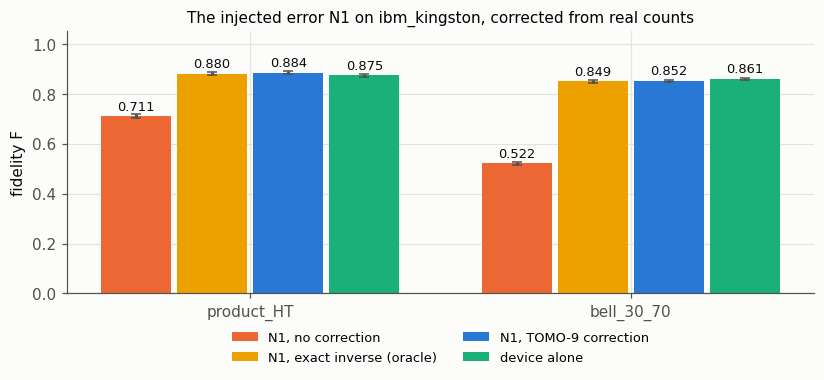

| message | F, no correction | F, TOMO-9 | F, device alone | recovered fraction f | σ (delta method) | Fieller 95 % | bootstrap 95 % |
|---|---|---|---|---|---|---|---|
| product_HT | 0.7109 | 0.8845 | 0.8751 | 1.0575 | 0.0569 | [0.952, 1.177] | [0.953, 1.171] |
| bell_30_70 | 0.5217 | 0.8523 | 0.8608 | 0.9751 | 0.0212 | [0.934, 1.017] | [0.935, 1.019] |

For both messages f = 1 lies inside the 95 % interval: **the correction learned from real counts recovers the whole injected loss.** It is also as good as the exact inverse: TOMO-9 − oracle = +0.0041 ± 0.0091 (product_HT); +0.0029 ± 0.0074 (bell_30_70).

In [7]:
order = [("R1_N1none", "no correction"), ("R1_N1oracle", "oracle (exact inverse)"), ("R2_N1corr", "TOMO-9 correction"),
         ("R1_nativeA", "native (no injected noise)")]
fig, ax = plt.subplots(figsize=(7.6, 3.6)); w = 0.2
for i, (pre, cond) in enumerate(order):
    bars = ax.bar(np.arange(2) + (i - 1.5) * w, [F(f"{pre}_{st}") for st in STATES], w * 0.92, yerr=[S(f"{pre}_{st}") for st in STATES],
                  color=CONDITION[cond], label=A.NAMES[pre], capsize=3, ecolor=INK_2)
    bar_labels(ax, bars, pad=0.012)
ax.set_xticks(range(2), STATES); ax.set_ylim(0, 1.05); ax.set_ylabel("fidelity F")
ax.set_title("The injected error N1 on ibm_kingston, corrected from real counts", fontsize=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8.5); plt.tight_layout(); plt.show()

rf = out["recovered_fraction"]
rows = [(r["state"], r["F"]["none"], r["F"]["corr"], r["F"]["native"], r["f"], r["sigma_delta"], fmt(r["fieller95"], 3),
         fmt([rf["bootstrap"]["results"][r["state"]]["f_q"][q] for q in ("0.025", "0.975")], 3)) for r in rf["rows"]]
show(md_table(rows, ["message", "F, no correction", "F, TOMO-9", "F, device alone", "recovered fraction f", "σ (delta method)",
                     "Fieller 95 %", "bootstrap 95 %"], 4))
show("For both messages f = 1 lies inside the 95 % interval: **the correction learned from real counts recovers the whole "
     "injected loss.** It is also as good as the exact inverse: TOMO-9 − oracle = "
     + "; ".join(f"{r['tomo_minus_oracle']:+.4f} ± {r['tomo_minus_oracle_sd']:.4f} ({r['state']})" for r in rf["rows"]) + ".")

**Predicted before it was run.** The twirl model of notebook 2 needs no simulator: each leg reaches Bob as the Pauli
channel diag(R T), with T from the Round 1 TOMO-9 and R the correction. Its predictions for Round 2 were saved and
hashed before Round 2 was sent.

In [8]:
tm = out["twirl_model"]
rows = []
for key, v in tm["blocks"].items():
    if key in r2["tomo"]:
        name, _, st = A.describe(key)
        rows.append((name, st, v["model_F"], F(key), F(key) - v["model_F"]))
show(md_table(rows, ["Round 2 block", "message", "predicted F (twirl model)", "hardware F", "hardware − predicted"], 4))
c = tm["check_round1"]
show(f"On the {c['n']} Round 1 blocks the model was not fitted to, the mean difference is {c['mean_diff']:+.4f} "
     f"(largest {c['max_abs_diff']:.4f}).")

| Round 2 block | message | predicted F (twirl model) | hardware F | hardware − predicted |
|---|---|---|---|---|
| device alone, TOMO-9 correction | product_HT | 0.8711 | 0.8726 | 0.0015 |
| device alone, TOMO-9 correction | bell_30_70 | 0.8552 | 0.8556 | 0.0004 |
| N1, TOMO-9 correction | product_HT | 0.8780 | 0.8845 | 0.0065 |
| N1, TOMO-9 correction | bell_30_70 | 0.8600 | 0.8523 | -0.0077 |
| 8 µs wait, TOMO-9 correction | product_HT | 0.7905 | 0.8089 | 0.0184 |
| 8 µs wait, TOMO-9 correction | bell_30_70 | 0.7672 | 0.7643 | -0.0029 |

On the 8 Round 1 blocks the model was not fitted to, the mean difference is -0.0052 (largest 0.0193).

## 6. A real error nobody recorded: an 8 µs wait, and dynamical decoupling

Letting the channel qubits wait 8 µs adds an error of the device itself. TOMO-9 splits it into a rotation (mostly
about z, a phase) and an incoherent remainder; the correction removes the rotation, while the remainder cannot be
undone by any unitary (the ceiling of notebook 5). IBM's dynamical decoupling (DD) refocuses z phases, but it also
pulses the idle message qubits, still in |0⟩. Through the static ZZ coupling ζ, each pulsed neighbour then adds a phase
π ζ t to its channel qubit. This explanation has no free parameter (Proposition P8.6, Observation O8.7).

In [9]:
n2, dd = out["n2"], out["dd"]
rows = [(*A.describe(k)[::2], v[0], v[1]) for k, v in n2["hardware"].items()]
show(md_table(rows, ["block", "message", "F", "σ"], 4))
th = {int(k): x for k, x in n2["theta"].items()}; kz = {int(k): x for k, x in n2["kHz"].items()}
show(f"The wait rotates leg q2 by {th[2]:.3f} rad and leg q3 by {th[3]:.3f} rad ({kz[2]:.1f} / {kz[3]:.1f} kHz over 8 µs).")
PLAIN = {"(the 8d reading)": "(the first reading of the data)", "(the planning version)": "(as assumed when planning)"}
def plain(s):
    for k, v in PLAIN.items():
        s = s.replace(k, v)
    return s
rows = [(plain(r["scenario"]), r["DD"], r["TOMO+DD"], r["chi2"], r["p"]) for r in dd["rows"]]
show(f"Each explanation predicts the two DD blocks with no fitted parameter (hardware: DD {dd['hardware']['DD'][0]:.3f} ± "
     f"{dd['hardware']['DD'][1]:.3f}, TOMO-9 + DD {dd['hardware']['TOMO+DD'][0]:.3f} ± {dd['hardware']['TOMO+DD'][1]:.3f}):")
show(md_table(rows, ["what DD does", "predicted F, DD", "predicted F, TOMO-9 + DD", "χ² (2 values)", "p"], 4))
ok = [r["scenario"].split(":")[0] for r in dd["rows"] if r["p"] > 0.05]
show(f"Only {' and '.join(ok)} agree with the data (p > 0.05); for every other explanation "
     f"p < {max(r['p'] for r in dd['rows'] if r['p'] <= 0.05):.0e}. Both have the pulsed neighbours adding a phase opposite "
     "to the waiting rotation. The correction learned *without* DD is wrong once DD is switched on, because DD itself "
     "changes the channel: correction and DD must be learned together.")

| block | message | F | σ |
|---|---|---|---|
| 8 µs wait, no correction | product_HT | 0.5623 | 0.0062 |
| 8 µs wait, TOMO-9 correction | product_HT | 0.8089 | 0.0062 |
| 8 µs wait, DD | product_HT | 0.7749 | 0.0070 |
| 8 µs wait, TOMO-9 correction + DD | product_HT | 0.4994 | 0.0067 |
| 8 µs wait, no correction | bell_30_70 | 0.5935 | 0.0069 |
| 8 µs wait, TOMO-9 correction | bell_30_70 | 0.7643 | 0.0059 |

The wait rotates leg q2 by 0.642 rad and leg q3 by 1.122 rad (12.8 / 22.3 kHz over 8 µs).

Each explanation predicts the two DD blocks with no fitted parameter (hardware: DD 0.775 ± 0.007, TOMO-9 + DD 0.499 ± 0.007):

| what DD does | predicted F, DD | predicted F, TOMO-9 + DD | χ² (2 values) | p |
|---|---|---|---|---|
| S1: DD refocuses every Z phase, keeps the non-Z native rotation; pulsed spectators add pi zeta t | 0.7859 | 0.4938 | 3.1735 | 0.2046 |
| S0: as S1, but DD also removes the non-Z native rotation (as assumed when planning) | 0.7863 | 0.4928 | 3.6758 | 0.1591 |
| S2: as S1, but DD leaves the whole native rotation | 0.7885 | 0.5416 | 43.6396 | 3.34e-10 |
| A1: no spectator phase (DD refocuses every Z phase only) | 0.7901 | 0.5435 | 48.1942 | 3.43e-11 |
| A0: no spectator phase, DD removes the whole rotation | 0.7905 | 0.5424 | 46.2422 | 9.09e-11 |
| S1': spectator phase in the same sense as the waiting rotation | 0.7860 | 0.5911 | 189.8520 | 5.95e-42 |
| B: in-pair ZZ survives DD (the first reading of the data) | 0.7736 | 0.6319 | 391.1536 | 1.15e-85 |

Only S1 and S0 agree with the data (p > 0.05); for every other explanation p < 3e-10. Both have the pulsed neighbours adding a phase opposite to the waiting rotation. The correction learned *without* DD is wrong once DD is switched on, because DD itself changes the channel: correction and DD must be learned together.

## 7. Where the fidelity of the device goes

From the ideal circuit to the hardware, for the device alone: the ideal device; a simulator built from IBM's
calibration record (the *twin*); the twin with the real timing of the circuit (this was the prediction); the twin
with the readout *measured* in Round 1; the hardware. The twin values are saved simulation results of the project
(the twin is not part of this repository). They are themselves tomography estimates, so the ideal value can exceed 1
by shot noise.

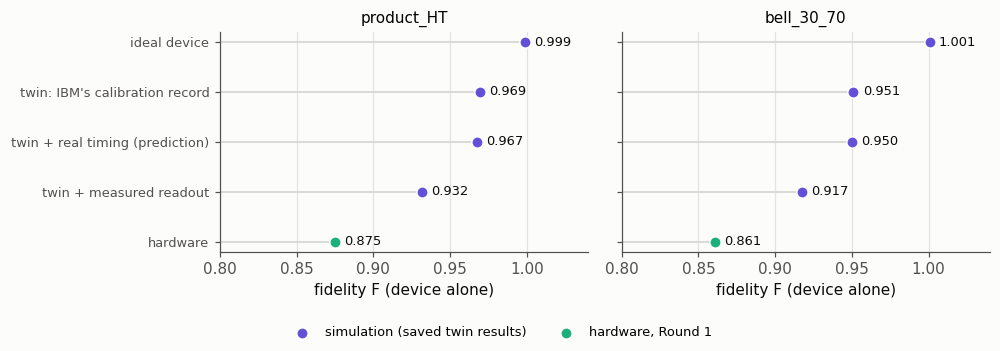

The prediction was 0.092 / 0.090 above the hardware (product_HT / bell_30_70). Using the readout measured in Round 1 instead of IBM's record explains 0.036 / 0.033 of it (the readout of message qubit q0 alone costs about 0.037); the remaining 0.057 / 0.057 is not explained by the twin.

In [10]:
eb = out["error_budget"]
LADDER = ["ideal device", "twin: IBM's calibration record", "twin + real timing (prediction)", "twin + measured readout", "hardware"]
fig, axs = plt.subplots(1, 2, figsize=(9.2, 3.2), sharey=True)
for ax, st in zip(axs, STATES):
    val = [x for _, x in eb["waterfall"][st]]
    y = np.arange(len(val))[::-1]
    ax.hlines(y, 0.8, val, color="#d9d8d3", lw=1.2)
    ax.scatter(val[:-1], y[:-1], s=55, color=SLOTS[6], zorder=3, edgecolor="white", label="simulation (saved twin results)")
    ax.scatter(val[-1:], y[-1:], s=55, color=CONDITION["native (no injected noise)"], zorder=3, edgecolor="white", label="hardware, Round 1")
    for yy, vv in zip(y, val):
        ax.text(vv + 0.006, yy, f"{vv:.3f}", va="center", fontsize=8.5, color=INK)
    ax.set_yticks(y, LADDER, fontsize=8.5); ax.set_xlim(0.8, 1.04); ax.grid(axis="y", visible=False)
    ax.set_title(st, fontsize=10); ax.set_xlabel("fidelity F (device alone)")
h, l = axs[1].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, fontsize=8.5)
plt.tight_layout(rect=(0, 0.09, 1, 1)); plt.show()
wf = {st: [x for _, x in eb["waterfall"][st]] for st in STATES}
show("The prediction was " + " / ".join(f"{wf[st][2] - wf[st][4]:.3f}" for st in STATES) + " above the hardware (product_HT / bell_30_70). "
     "Using the readout measured in Round 1 instead of IBM's record explains " + " / ".join(f"{wf[st][2] - wf[st][3]:.3f}" for st in STATES)
     + f" of it (the readout of message qubit q0 alone costs about {eb['q41_cost_product']:.3f}); the remaining "
     + " / ".join(f"{wf[st][3] - wf[st][4]:.3f}" for st in STATES) + " is not explained by the twin.")

## 8. Predictions against outcomes

Every hypothesis was written down, with its pass / fail rule, before the first job was sent. The ones with a verdict:

In [11]:
PLAIN_H = {"H1": "The device alone reaches its predicted band, with no native rotation above 0.05 rad.",
           "H2": "TOMO-9 from real counts recovers the whole injected N1 loss.",
           "H3": "The learned correction is as good as the exact inverse (oracle), within noise.",
           "H5/H10": "Readout errors lower F but do not spoil the correction.",
           "H6": "With Bob's readout mitigated, the versions order A > C > B, all within about 0.01.",
           "H7": "The twin built from IBM's calibration record is optimistic.",
           "H8": "The crosstalk detector stays silent."}
fr = {r["state"]: r for r in out["recovered_fraction"]["rows"]}
hy = {h["id"]: h for h in out["hypotheses"]}
nat = " / ".join(f"{F('R1_nativeA_' + st):.3f}" for st in STATES)
fs = " / ".join(f"{fr[st]['f']:.3f}" for st in STATES)
d_or = " / ".join(f"{fr[st]['tomo_minus_oracle']:+.4f}" for st in STATES)
EVIDENCE = {"H1": f"F = {nat}, below the band; native rotation {out['corr']['fingerprint_angle']:.3f} rad (section 4)",
            "H2": f"f = {fs} (section 5)",
            "H3": f"TOMO-9 − oracle = {d_or} (section 5)",
            "H5/H10": hy["H5/H10"]["evidence"].replace(" - ", " − "),
            "H6": "Bob-mitigated F (product_HT): " + hy["H6"]["evidence"],
            "H7": hy["H7"]["evidence"].replace("L3 prediction", "twin's prediction"),
            "H8": f"p = {r1['detector_fp']['p']:.2g} (device alone), {r1['detector_cal']['p']:.3g} (with N1) (section 4)"}
rows = [(h["id"], PLAIN_H[h["id"]], EVIDENCE[h["id"]], "holds" if h["holds"] else "**fails**")
        for h in out["hypotheses"] if h["holds"] is not None]
show(md_table(rows, ["", "hypothesis", "evidence", "verdict"], 3))
cmp = [r for r in out["compare"] if r.get("band")]
show("The claims about the correction held; the predicted absolute level of the device did not: " + "; ".join(
     f"Round {n}: {sum(r['inside_band'] for r in cmp if r['round'] == n)} of {sum(r['round'] == n for r in cmp)} blocks inside their "
     f"predicted band, {sum(r['diff'] < 0 for r in cmp if r['round'] == n)} below the prediction" for n in (1, 2)) + ".")

|  | hypothesis | evidence | verdict |
|---|---|---|---|
| H1 | The device alone reaches its predicted band, with no native rotation above 0.05 rad. | F = 0.875 / 0.861, below the band; native rotation 0.159 rad (section 4) | **fails** |
| H2 | TOMO-9 from real counts recovers the whole injected N1 loss. | f = 1.057 / 0.975 (section 5) | holds |
| H3 | The learned correction is as good as the exact inverse (oracle), within noise. | TOMO-9 − oracle = +0.0041 / +0.0029 (section 5) | holds |
| H5/H10 | Readout errors lower F but do not spoil the correction. | product_HT: mitigated − raw = +0.0088; bell_30_70: mitigated − raw = +0.0128 | holds |
| H6 | With Bob's readout mitigated, the versions order A > C > B, all within about 0.01. | Bob-mitigated F (product_HT): A 0.884, C 0.919, B 0.882 | **fails** |
| H7 | The twin built from IBM's calibration record is optimistic. | 12 of 12 Round 1 blocks below the twin's prediction | holds |
| H8 | The crosstalk detector stays silent. | p = 0.00021 (device alone), 0.845 (with N1) (section 4) | **fails** |

The claims about the correction held; the predicted absolute level of the device did not: Round 1: 0 of 12 blocks inside their predicted band, 12 below the prediction; Round 2: 3 of 7 blocks inside their predicted band, 7 below the prediction.

## What it means

In [12]:
fr = {r["state"]: r for r in out["recovered_fraction"]["rows"]}
show(f"""
* **The correction works on real hardware.** Learned from 9 circuits of real counts, it recovers the whole injected error:
  f = {fr['product_HT']['f']:.3f} and {fr['bell_30_70']['f']:.3f}, with f = 1 inside both 95 % intervals, and it matches the exact inverse.
* **The twirl model predicts the hardware** from the TOMO-9 matrices alone, without a simulator.
* **A real device error is partly correctable.** The 8 µs wait goes from F = {n2['hardware']['R1_N2none_product_HT'][0]:.3f} to
  {n2['hardware']['R2_N2corr_product_HT'][0]:.3f} with the learned correction; the rest is incoherent and beyond any unitary.
* **DD and the correction interact**: DD changes the channel (pulsed neighbours), so the two must be learned together.
* **The twin was optimistic** in absolute fidelity: partly because the real readout was worse than IBM's record,
  partly for reasons it does not capture (section 7).
""")


* **The correction works on real hardware.** Learned from 9 circuits of real counts, it recovers the whole injected error:
  f = 1.057 and 0.975, with f = 1 inside both 95 % intervals, and it matches the exact inverse.
* **The twirl model predicts the hardware** from the TOMO-9 matrices alone, without a simulator.
* **A real device error is partly correctable.** The 8 µs wait goes from F = 0.562 to
  0.809 with the learned correction; the rest is incoherent and beyond any unitary.
* **DD and the correction interact**: DD changes the channel (pulsed neighbours), so the two must be learned together.
* **The twin was optimistic** in absolute fidelity: partly because the real readout was worse than IBM's record,
  partly for reasons it does not capture (section 7).


## What is left open

* One device on one day. Notebook 9 repeats the rounds three weeks later and on a second device.
* The two-qubit correction of notebook 6 and the drift tracking of notebook 7 were not run on hardware.
* Why the crosstalk detector fires on the device alone is not understood.
* Part of the native error is not explained by the twin.

---
**Reproducibility.** Every value in this notebook equals the saved result of the research project (`data/reference/`).
The same check runs in `tests/regression/test_hardware.py` and as `python -m telecorr.hardware reproduce --check`.

In [13]:
res = check(out)
assert all(nbad == 0 for _, _, nbad in res)
print(f"{sum(n for _, n, _ in res)} saved values compared, all reproduced exactly.")

4711 saved values compared, all reproduced exactly.
